In [1]:
import sys
print(sys.executable)

C:\Users\lucas\Downloads\Projects\Mining_Operations_Dashboard\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/mining_operations_data.csv")

df.head()

,Date,Rig_ID,Site,Shift,Planned_Meters,Actual_Meters,Downtime_Hours,Fuel_Consumption_L,Samples_Collected,Operator_ID,Maintenance_Flag
0,2026-01-01,RIG-001,North Pit,Day,110,104,0.59,160.05,9,OP-009,No
1,2026-01-01,RIG-002,North Pit,Night,113,94,3.09,175.00,10,OP-006,No
2,2026-01-01,RIG-003,South Pit,Night,77,67,3.09,117.03,5,OP-009,No
3,2026-01-01,RIG-004,South Pit,Night,91,80,2.15,152.47,8,OP-006,No
4,2026-01-02,RIG-001,North Pit,Day,96,73,3.63,118.53,7,OP-002,No


In [3]:
df.shape

(360, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                360 non-null    str    
 1   Rig_ID              360 non-null    str    
 2   Site                360 non-null    str    
 3   Shift               360 non-null    str    
 4   Planned_Meters      360 non-null    int64  
 5   Actual_Meters       360 non-null    int64  
 6   Downtime_Hours      360 non-null    float64
 7   Fuel_Consumption_L  360 non-null    float64
 8   Samples_Collected   360 non-null    int64  
 9   Operator_ID         360 non-null    str    
 10  Maintenance_Flag    360 non-null    str    
dtypes: float64(2), int64(3), str(6)
memory usage: 31.1 KB


In [5]:
df["Date"] = pd.to_datetime(df["Date"])

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                360 non-null    datetime64[us]
 1   Rig_ID              360 non-null    str           
 2   Site                360 non-null    str           
 3   Shift               360 non-null    str           
 4   Planned_Meters      360 non-null    int64         
 5   Actual_Meters       360 non-null    int64         
 6   Downtime_Hours      360 non-null    float64       
 7   Fuel_Consumption_L  360 non-null    float64       
 8   Samples_Collected   360 non-null    int64         
 9   Operator_ID         360 non-null    str           
 10  Maintenance_Flag    360 non-null    str           
dtypes: datetime64[us](1), float64(2), int64(3), str(5)
memory usage: 31.1 KB


In [6]:
df.describe()

,Date,Planned_Meters,Actual_Meters,Downtime_Hours,Fuel_Consumption_L,Samples_Collected
count,360,360.000000,360.000000,360.000000,360.000000,360.000000
mean,2026-02-14 12:00:00,98.019444,81.058333,1.983778,139.817694,7.933333
min,2026-01-01 00:00:00,75.000000,45.000000,0.030000,82.270000,4.000000
25%,2026-01-23 00:00:00,86.000000,69.000000,0.837500,119.292500,6.000000
50%,2026-02-14 12:00:00,98.500000,80.000000,1.690000,136.555000,8.000000
75%,2026-03-09 00:00:00,109.000000,92.000000,2.870000,157.890000,9.000000
max,2026-03-31 00:00:00,120.000000,126.000000,8.000000,216.340000,13.000000
std,NaN,13.506303,15.583165,1.466784,27.436478,1.938037


In [7]:
total_planned = df["Planned_Meters"].sum()
total_actual = df["Actual_Meters"].sum()

achievement_rate = (total_actual / total_planned) * 100

print(f"Total Planned Meters: {total_planned:,} m")
print(f"Total Actual Meters: {total_actual:,} m")
print(f"Drilling Achievement Rate: {achievement_rate:.2f}%")

Total Planned Meters: 35,287 m
Total Actual Meters: 29,181 m
Drilling Achievement Rate: 82.70%


In [8]:
rig_performance = df.groupby("Rig_ID").agg(
    Planned_Meters=("Planned_Meters", "sum"),
    Actual_Meters=("Actual_Meters", "sum"),
    Downtime_Hours=("Downtime_Hours", "sum"),
    Fuel_Consumption_L=("Fuel_Consumption_L", "sum")
)

rig_performance["Achievement_Rate"] = (
    rig_performance["Actual_Meters"] /
    rig_performance["Planned_Meters"] * 100
)

rig_performance.round(2)

,Planned_Meters,Actual_Meters,Downtime_Hours,Fuel_Consumption_L,Achievement_Rate
Rig_ID,,,,,
RIG-001,8781,7215,189.21,12276.54,82.17
RIG-002,9074,7581,186.04,13205.10,83.55
RIG-003,8650,7129,171.96,12323.61,82.42
RIG-004,8782,7256,166.95,12529.12,82.62


In [9]:
rig_performance["Meters_per_Downtime_Hour"] = (
    rig_performance["Actual_Meters"] /
    rig_performance["Downtime_Hours"]
)

rig_performance.round(2)

,Planned_Meters,Actual_Meters,Downtime_Hours,Fuel_Consumption_L,Achievement_Rate,Meters_per_Downtime_Hour
Rig_ID,,,,,,
RIG-001,8781,7215,189.21,12276.54,82.17,38.13
RIG-002,9074,7581,186.04,13205.10,83.55,40.75
RIG-003,8650,7129,171.96,12323.61,82.42,41.46
RIG-004,8782,7256,166.95,12529.12,82.62,43.46


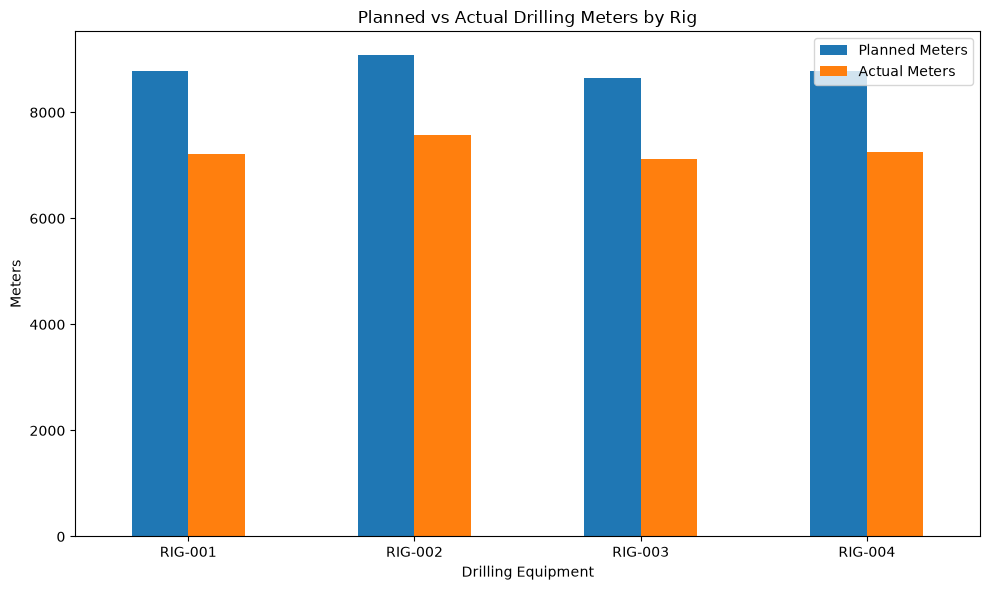

In [10]:
import matplotlib.pyplot as plt

rig_performance[["Planned_Meters", "Actual_Meters"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Planned vs Actual Drilling Meters by Rig")
plt.xlabel("Drilling Equipment")
plt.ylabel("Meters")
plt.xticks(rotation=0)
plt.legend(["Planned Meters", "Actual Meters"])
plt.tight_layout()
plt.show()

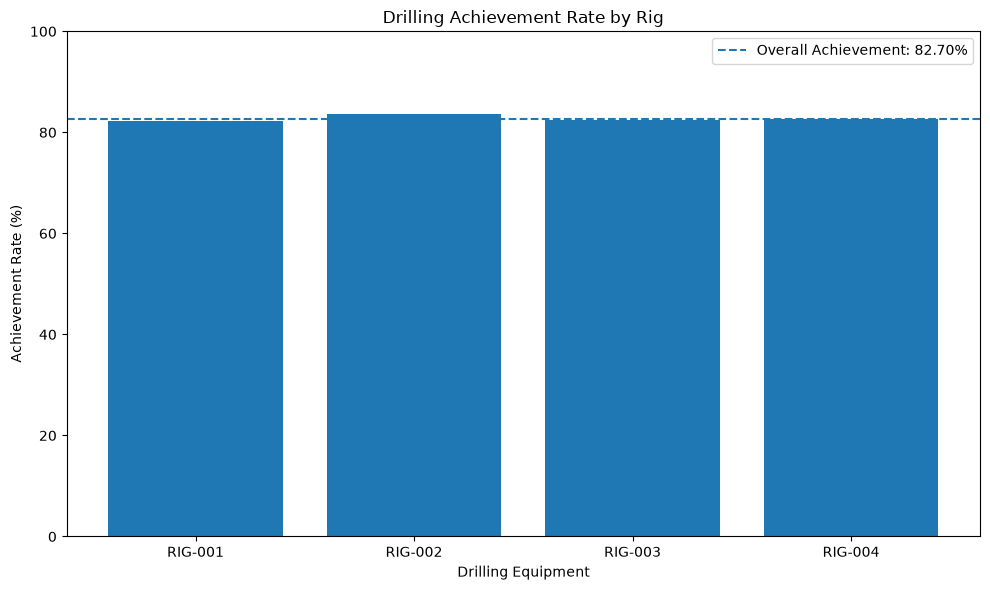

In [11]:
plt.figure(figsize=(10, 6))

plt.bar(
    rig_performance.index,
    rig_performance["Achievement_Rate"]
)

plt.title("Drilling Achievement Rate by Rig")
plt.xlabel("Drilling Equipment")
plt.ylabel("Achievement Rate (%)")

plt.ylim(0, 100)

plt.axhline(
    y=achievement_rate,
    linestyle="--",
    label=f"Overall Achievement: {achievement_rate:.2f}%"
)

plt.legend()
plt.tight_layout()
plt.show()

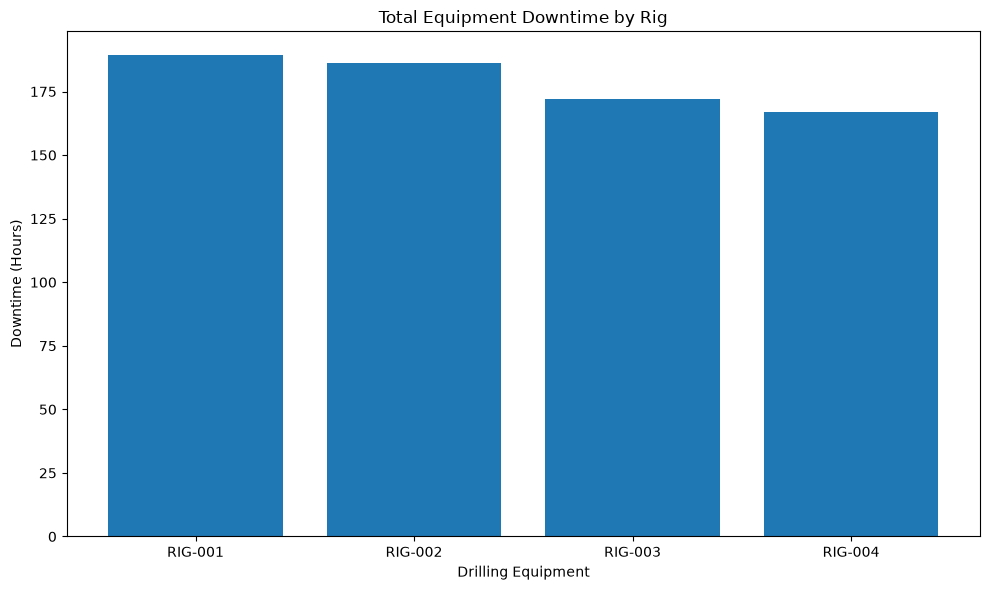

In [12]:
plt.figure(figsize=(10, 6))

plt.bar(
    rig_performance.index,
    rig_performance["Downtime_Hours"]
)

plt.title("Total Equipment Downtime by Rig")
plt.xlabel("Drilling Equipment")
plt.ylabel("Downtime (Hours)")

plt.tight_layout()
plt.show()

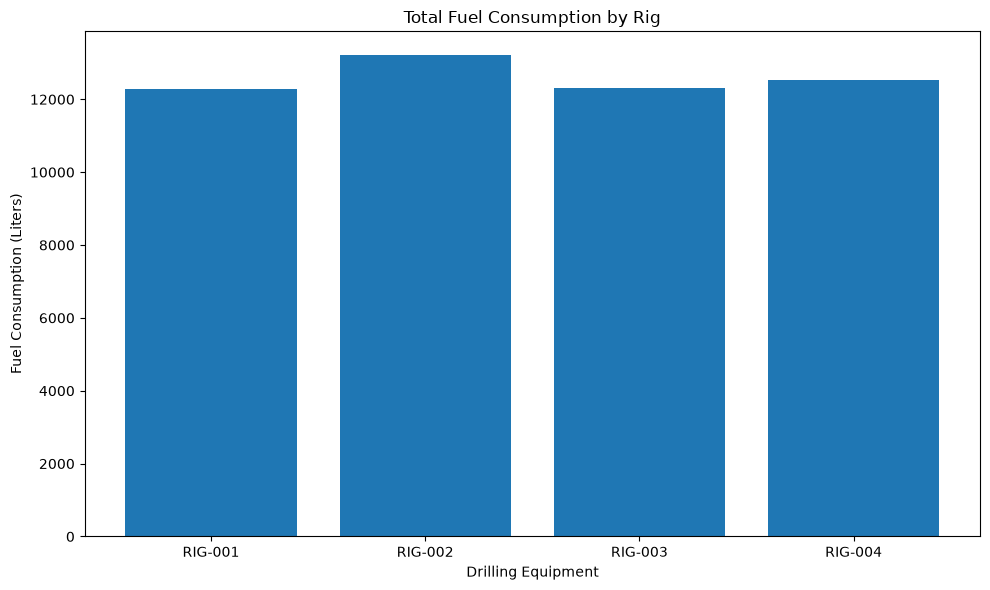

In [13]:
plt.figure(figsize=(10, 6))

plt.bar(
    rig_performance.index,
    rig_performance["Fuel_Consumption_L"]
)

plt.title("Total Fuel Consumption by Rig")
plt.xlabel("Drilling Equipment")
plt.ylabel("Fuel Consumption (Liters)")

plt.tight_layout()
plt.show()

In [14]:
rig_performance["Fuel_per_Meter"] = (
    rig_performance["Fuel_Consumption_L"] /
    rig_performance["Actual_Meters"]
)

rig_performance[
    ["Fuel_Consumption_L", "Actual_Meters", "Fuel_per_Meter"]
].round(3)

,Fuel_Consumption_L,Actual_Meters,Fuel_per_Meter
Rig_ID,,,
RIG-001,12276.54,7215,1.702
RIG-002,13205.10,7581,1.742
RIG-003,12323.61,7129,1.729
RIG-004,12529.12,7256,1.727


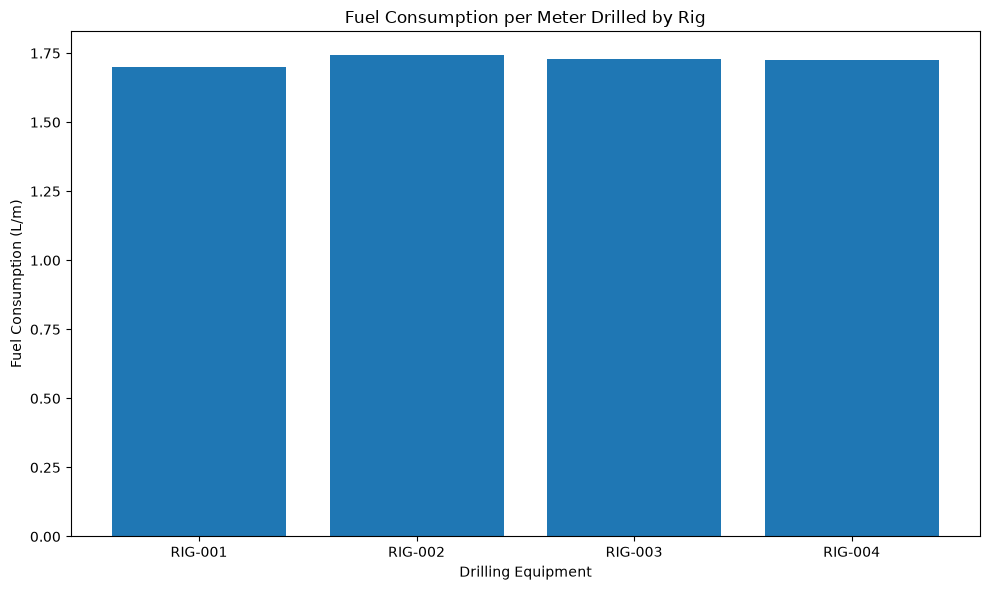

In [15]:
plt.figure(figsize=(10, 6))

plt.bar(
    rig_performance.index,
    rig_performance["Fuel_per_Meter"]
)

plt.title("Fuel Consumption per Meter Drilled by Rig")
plt.xlabel("Drilling Equipment")
plt.ylabel("Fuel Consumption (L/m)")

plt.tight_layout()
plt.show()

In [16]:
shift_performance = df.groupby("Shift").agg(
    Planned_Meters=("Planned_Meters", "sum"),
    Actual_Meters=("Actual_Meters", "sum"),
    Downtime_Hours=("Downtime_Hours", "sum"),
    Fuel_Consumption_L=("Fuel_Consumption_L", "sum"),
    Samples_Collected=("Samples_Collected", "sum")
)

shift_performance["Achievement_Rate"] = (
    shift_performance["Actual_Meters"] /
    shift_performance["Planned_Meters"] * 100
)

shift_performance.round(2)

,Planned_Meters,Actual_Meters,Downtime_Hours,Fuel_Consumption_L,Samples_Collected,Achievement_Rate
Shift,,,,,,
Day,18000,14793,372.13,25567.93,1463,82.18
Night,17287,14388,342.03,24766.44,1393,83.23


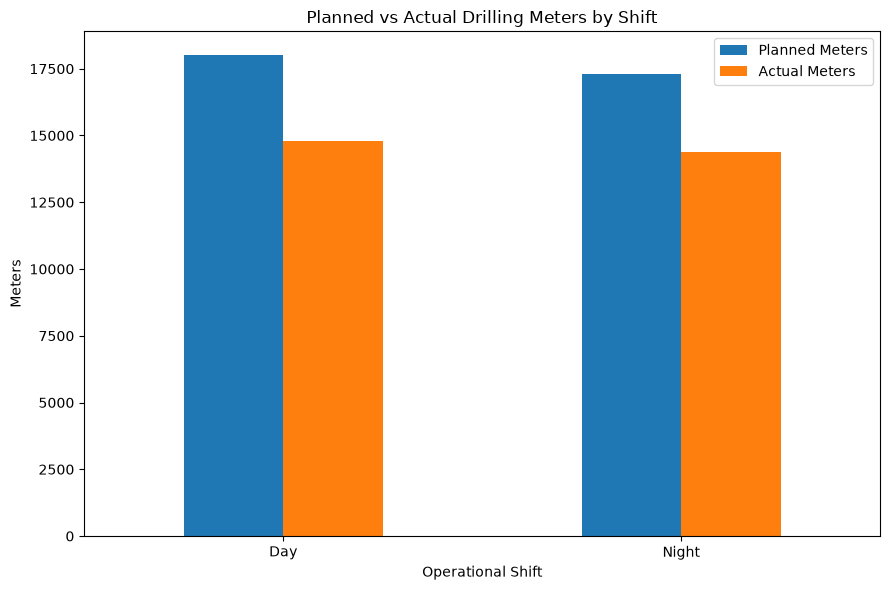

In [17]:
shift_performance[
    ["Planned_Meters", "Actual_Meters"]
].plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Planned vs Actual Drilling Meters by Shift")
plt.xlabel("Operational Shift")
plt.ylabel("Meters")
plt.xticks(rotation=0)
plt.legend(["Planned Meters", "Actual Meters"])
plt.tight_layout()
plt.show()

In [18]:
shift_performance["Fuel_per_Meter"] = (
    shift_performance["Fuel_Consumption_L"] /
    shift_performance["Actual_Meters"]
)

shift_performance[
    ["Fuel_Consumption_L", "Actual_Meters", "Fuel_per_Meter"]
].round(3)

,Fuel_Consumption_L,Actual_Meters,Fuel_per_Meter
Shift,,,
Day,25567.93,14793,1.728
Night,24766.44,14388,1.721


In [19]:
site_performance = df.groupby("Site").agg(
    Planned_Meters=("Planned_Meters", "sum"),
    Actual_Meters=("Actual_Meters", "sum"),
    Downtime_Hours=("Downtime_Hours", "sum"),
    Fuel_Consumption_L=("Fuel_Consumption_L", "sum"),
    Samples_Collected=("Samples_Collected", "sum")
)

site_performance["Achievement_Rate"] = (
    site_performance["Actual_Meters"] /
    site_performance["Planned_Meters"] * 100
)

site_performance["Fuel_per_Meter"] = (
    site_performance["Fuel_Consumption_L"] /
    site_performance["Actual_Meters"]
)

site_performance.round(2)

,Planned_Meters,Actual_Meters,Downtime_Hours,Fuel_Consumption_L,Samples_Collected,Achievement_Rate,Fuel_per_Meter
Site,,,,,,,
North Pit,17855,14796,375.25,25481.64,1463,82.87,1.72
South Pit,17432,14385,338.91,24852.73,1393,82.52,1.73


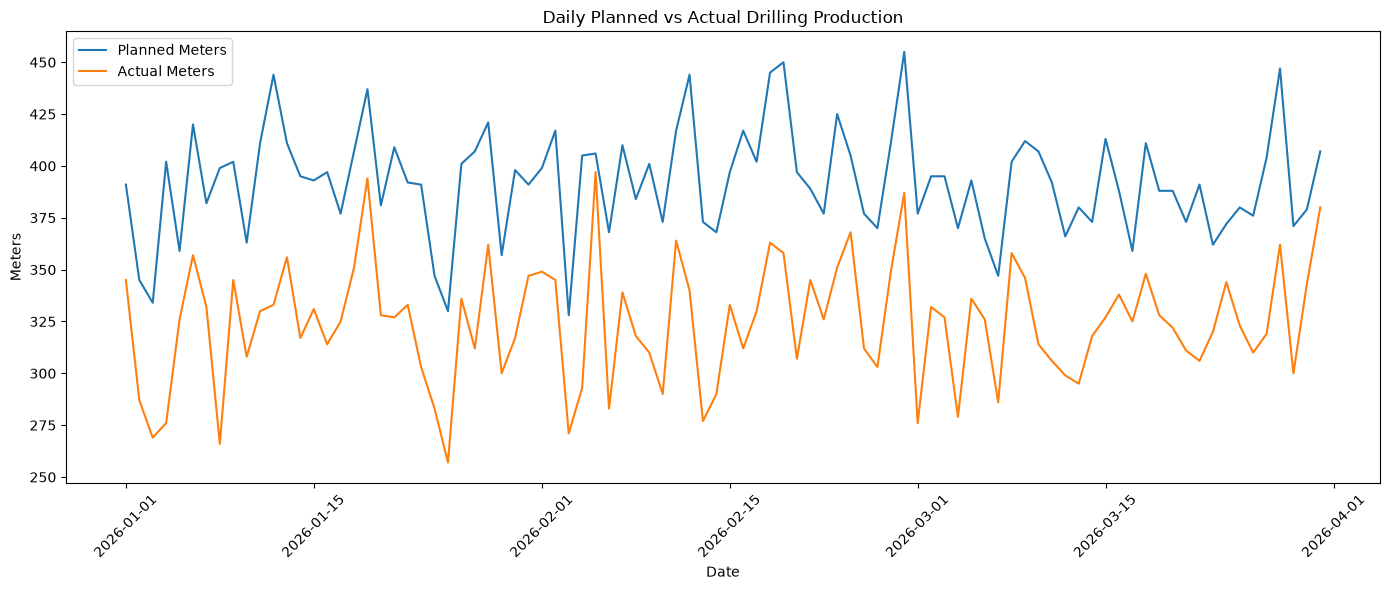

In [20]:
daily_performance = df.groupby("Date").agg(
    Planned_Meters=("Planned_Meters", "sum"),
    Actual_Meters=("Actual_Meters", "sum")
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_performance.index,
    daily_performance["Planned_Meters"],
    label="Planned Meters"
)

plt.plot(
    daily_performance.index,
    daily_performance["Actual_Meters"],
    label="Actual Meters"
)

plt.title("Daily Planned vs Actual Drilling Production")
plt.xlabel("Date")
plt.ylabel("Meters")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
best_day = daily_performance["Actual_Meters"].idxmax()
worst_day = daily_performance["Actual_Meters"].idxmin()

best_production = daily_performance.loc[best_day, "Actual_Meters"]
worst_production = daily_performance.loc[worst_day, "Actual_Meters"]

print("Best Production Day:")
print(f"Date: {best_day.strftime('%Y-%m-%d')}")
print(f"Actual Production: {best_production:.0f} meters")

print("\nWorst Production Day:")
print(f"Date: {worst_day.strftime('%Y-%m-%d')}")
print(f"Actual Production: {worst_production:.0f} meters")

Best Production Day:
Date: 2026-02-05
Actual Production: 397 meters

Worst Production Day:
Date: 2026-01-25
Actual Production: 257 meters


In [22]:
average_daily_production = daily_performance["Actual_Meters"].mean()

days_below_average = (
    daily_performance["Actual_Meters"] < average_daily_production
).sum()

days_above_average = (
    daily_performance["Actual_Meters"] >= average_daily_production
).sum()

print(f"Average Daily Production: {average_daily_production:.2f} meters")
print(f"Days Below Average: {days_below_average}")
print(f"Days At or Above Average: {days_above_average}")

Average Daily Production: 324.23 meters
Days Below Average: 41
Days At or Above Average: 49


In [23]:
daily_downtime = df.groupby("Date").agg(
    Actual_Meters=("Actual_Meters", "sum"),
    Downtime_Hours=("Downtime_Hours", "sum")
)

daily_downtime.corr()

,Actual_Meters,Downtime_Hours
Actual_Meters,1.000000,-0.385797
Downtime_Hours,-0.385797,1.000000


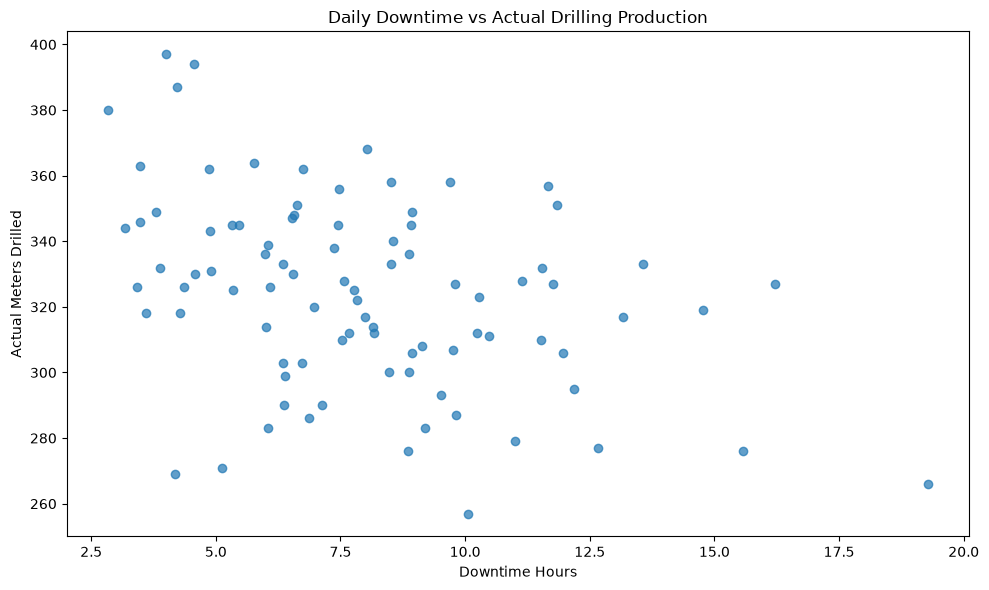

In [24]:
plt.figure(figsize=(10, 6))

plt.scatter(
    daily_downtime["Downtime_Hours"],
    daily_downtime["Actual_Meters"],
    alpha=0.7
)

plt.title("Daily Downtime vs Actual Drilling Production")
plt.xlabel("Downtime Hours")
plt.ylabel("Actual Meters Drilled")

plt.tight_layout()
plt.show()

In [25]:
maintenance_analysis = df.groupby("Maintenance_Flag").agg(
    Total_Records=("Rig_ID", "count"),
    Planned_Meters=("Planned_Meters", "sum"),
    Actual_Meters=("Actual_Meters", "sum"),
    Downtime_Hours=("Downtime_Hours", "sum"),
    Fuel_Consumption_L=("Fuel_Consumption_L", "sum")
)

maintenance_analysis["Achievement_Rate"] = (
    maintenance_analysis["Actual_Meters"] /
    maintenance_analysis["Planned_Meters"] * 100
)

maintenance_analysis.round(2)

,Total_Records,Planned_Meters,Actual_Meters,Downtime_Hours,Fuel_Consumption_L,Achievement_Rate
Maintenance_Flag,,,,,,
No,327,32139,26891,567.35,46389.88,83.67
Yes,33,3148,2290,146.81,3944.49,72.74


In [26]:
maintenance_analysis["Avg_Planned_Meters"] = (
    maintenance_analysis["Planned_Meters"] /
    maintenance_analysis["Total_Records"]
)

maintenance_analysis["Avg_Actual_Meters"] = (
    maintenance_analysis["Actual_Meters"] /
    maintenance_analysis["Total_Records"]
)

maintenance_analysis["Avg_Downtime_Hours"] = (
    maintenance_analysis["Downtime_Hours"] /
    maintenance_analysis["Total_Records"]
)

maintenance_analysis["Fuel_per_Meter"] = (
    maintenance_analysis["Fuel_Consumption_L"] /
    maintenance_analysis["Actual_Meters"]
)

maintenance_analysis.round(2)

,Total_Records,Planned_Meters,Actual_Meters,Downtime_Hours,Fuel_Consumption_L,Achievement_Rate,Avg_Planned_Meters,Avg_Actual_Meters,Avg_Downtime_Hours,Fuel_per_Meter
Maintenance_Flag,,,,,,,,,,
No,327,32139,26891,567.35,46389.88,83.67,98.28,82.24,1.74,1.73
Yes,33,3148,2290,146.81,3944.49,72.74,95.39,69.39,4.45,1.72


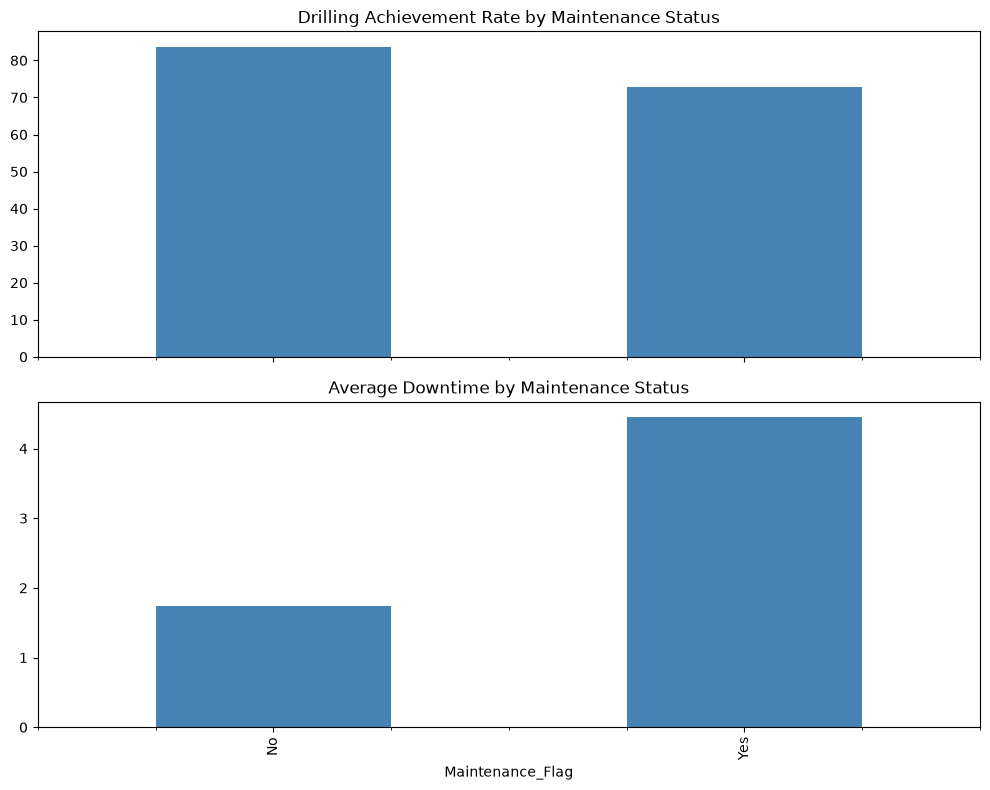

In [27]:
maintenance_comparison = df.groupby("Maintenance_Flag").agg(
    Achievement_Rate=(
        "Actual_Meters",
        lambda x: x.sum() / df.loc[x.index, "Planned_Meters"].sum() * 100
    ),
    Avg_Downtime_Hours=("Downtime_Hours", "mean")
)

maintenance_comparison.plot(
    kind="bar",
    subplots=True,
    figsize=(10, 8),
    layout=(2, 1),
    legend=False,
    color=["steelblue"],
    title=[
        "Drilling Achievement Rate by Maintenance Status",
        "Average Downtime by Maintenance Status"
    ]
)

plt.tight_layout()
plt.show()

In [28]:
operator_performance = df.groupby("Operator_ID").agg(
    Total_Records=("Rig_ID", "count"),
    Planned_Meters=("Planned_Meters", "sum"),
    Actual_Meters=("Actual_Meters", "sum"),
    Downtime_Hours=("Downtime_Hours", "sum"),
    Fuel_Consumption_L=("Fuel_Consumption_L", "sum"),
    Samples_Collected=("Samples_Collected", "sum")
)

operator_performance["Achievement_Rate"] = (
    operator_performance["Actual_Meters"] /
    operator_performance["Planned_Meters"] * 100
)

operator_performance["Avg_Actual_Meters"] = (
    operator_performance["Actual_Meters"] /
    operator_performance["Total_Records"]
)

operator_performance.round(2)

,Total_Records,Planned_Meters,Actual_Meters,Downtime_Hours,Fuel_Consumption_L,Samples_Collected,Achievement_Rate,Avg_Actual_Meters
Operator_ID,,,,,,,,
OP-001,18,1769,1429,33.01,2460.87,143,80.78,79.39
OP-002,41,4045,3363,83.84,5794.77,322,83.14,82.02
OP-003,44,4194,3394,81.72,5927.82,328,80.93,77.14
OP-004,31,3070,2554,57.44,4357.76,262,83.19,82.39
OP-005,27,2672,2155,59.76,3743.79,215,80.65,79.81
OP-006,35,3381,2773,64.97,4821.03,265,82.02,79.23
OP-007,33,3294,2731,60.61,4567.06,260,82.91,82.76
OP-008,28,2771,2331,59.33,4196.65,233,84.12,83.25
OP-009,26,2589,2245,42.48,3790.28,227,86.71,86.35


In [1]:
maintenance_comparison = df.groupby("Maintenance_Flag").agg(
    Achievement_Rate=(
        "Actual_Meters",
        lambda x: x.sum() / df.loc[x.index, "Planned_Meters"].sum() * 100
    ),
    Avg_Downtime_Hours=("Downtime_Hours", "mean")
)

maintenance_comparison.plot(
    kind="bar",
    subplots=True,
    figsize=(10, 8),
    layout=(2, 1),
    legend=False,
    color=["steelblue"],
    title=[
        "Drilling Achievement Rate by Maintenance Status",
        "Average Downtime by Maintenance Status"
    ]
)

plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/mining_operations_data.csv")

df["Date"] = pd.to_datetime(df["Date"])

df.head()

,Date,Rig_ID,Site,Shift,Planned_Meters,Actual_Meters,Downtime_Hours,Fuel_Consumption_L,Samples_Collected,Operator_ID,Maintenance_Flag
0,2026-01-01,RIG-001,North Pit,Day,110,104,0.59,160.05,9,OP-009,No
1,2026-01-01,RIG-002,North Pit,Night,113,94,3.09,175.00,10,OP-006,No
2,2026-01-01,RIG-003,South Pit,Night,77,67,3.09,117.03,5,OP-009,No
3,2026-01-01,RIG-004,South Pit,Night,91,80,2.15,152.47,8,OP-006,No
4,2026-01-02,RIG-001,North Pit,Day,96,73,3.63,118.53,7,OP-002,No


In [3]:
df.shape

(360, 11)

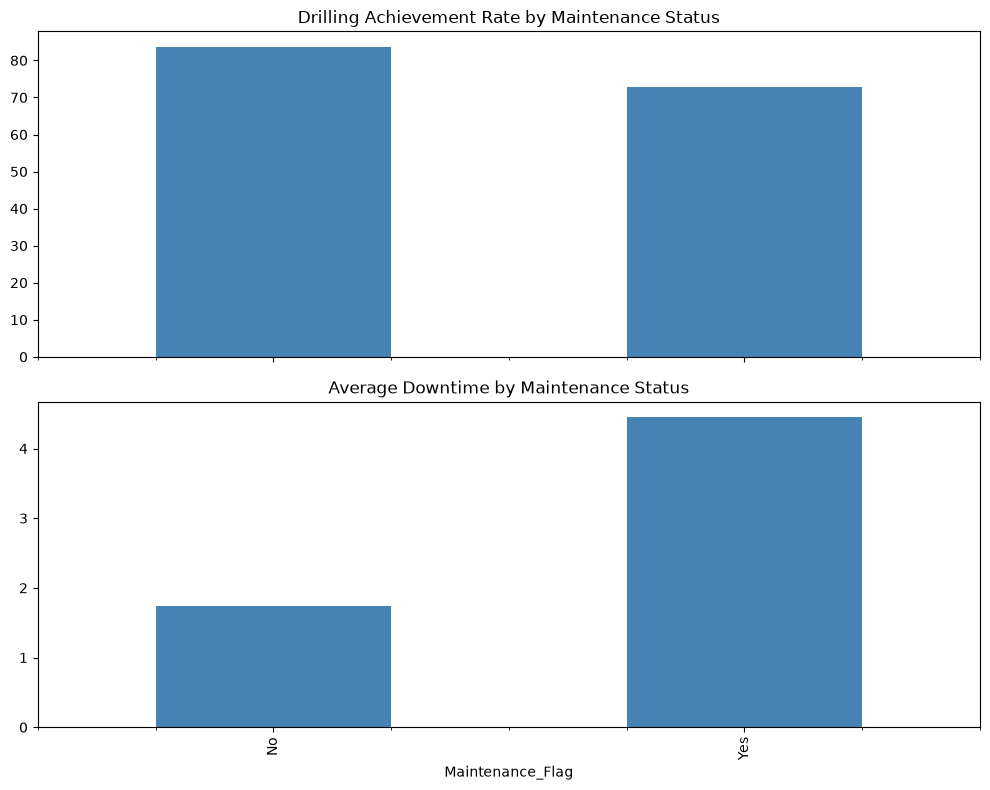

In [4]:
maintenance_comparison = df.groupby("Maintenance_Flag").agg(
    Achievement_Rate=(
        "Actual_Meters",
        lambda x: x.sum() / df.loc[x.index, "Planned_Meters"].sum() * 100
    ),
    Avg_Downtime_Hours=("Downtime_Hours", "mean")
)

maintenance_comparison.plot(
    kind="bar",
    subplots=True,
    figsize=(10, 8),
    layout=(2, 1),
    legend=False,
    color=["steelblue"],
    title=[
        "Drilling Achievement Rate by Maintenance Status",
        "Average Downtime by Maintenance Status"
    ]
)

plt.tight_layout()
plt.show()

In [5]:
operator_performance = df.groupby("Operator_ID").agg(
    Total_Records=("Rig_ID", "count"),
    Planned_Meters=("Planned_Meters", "sum"),
    Actual_Meters=("Actual_Meters", "sum"),
    Downtime_Hours=("Downtime_Hours", "sum"),
    Samples_Collected=("Samples_Collected", "sum")
)

operator_performance["Achievement_Rate"] = (
    operator_performance["Actual_Meters"] /
    operator_performance["Planned_Meters"] * 100
)

operator_performance["Avg_Actual_Meters"] = (
    operator_performance["Actual_Meters"] /
    operator_performance["Total_Records"]
)

operator_performance = operator_performance.sort_values(
    by="Achievement_Rate",
    ascending=False
)

operator_performance.round(2)

,Total_Records,Planned_Meters,Actual_Meters,Downtime_Hours,Samples_Collected,Achievement_Rate,Avg_Actual_Meters
Operator_ID,,,,,,,
OP-009,26,2589,2245,42.48,227,86.71,86.35
OP-012,25,2371,1999,49.76,199,84.31,79.96
OP-008,28,2771,2331,59.33,233,84.12,83.25
OP-010,25,2380,2000,57.63,192,84.03,80.00
OP-004,31,3070,2554,57.44,262,83.19,82.39
OP-002,41,4045,3363,83.84,322,83.14,82.02
OP-007,33,3294,2731,60.61,260,82.91,82.76
OP-006,35,3381,2773,64.97,265,82.02,79.23
OP-003,44,4194,3394,81.72,328,80.93,77.14


In [6]:
operator_performance["Avg_Downtime_Hours"] = (
    operator_performance["Downtime_Hours"] /
    operator_performance["Total_Records"]
)

operator_downtime = operator_performance[
    ["Avg_Downtime_Hours", "Achievement_Rate"]
].sort_values(
    by="Avg_Downtime_Hours",
    ascending=False
)

operator_downtime.round(2)

,Avg_Downtime_Hours,Achievement_Rate
Operator_ID,,
OP-011,2.36,80.23
OP-010,2.31,84.03
OP-005,2.21,80.65
OP-008,2.12,84.12
OP-002,2.04,83.14
OP-012,1.99,84.31
OP-003,1.86,80.93
OP-006,1.86,82.02
OP-004,1.85,83.19


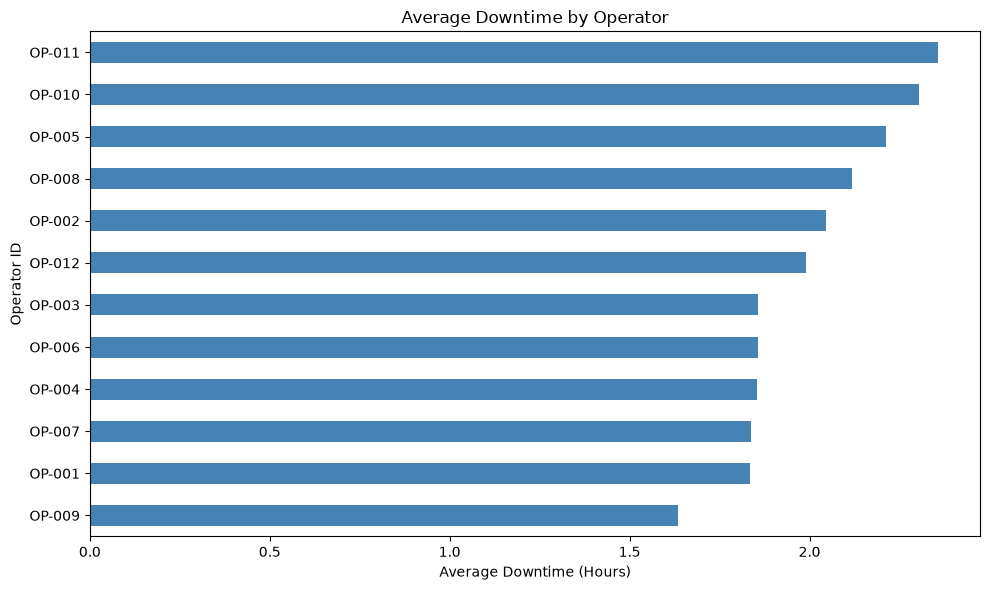

In [7]:
operator_downtime["Avg_Downtime_Hours"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Average Downtime by Operator",
    xlabel="Average Downtime (Hours)",
    ylabel="Operator ID",
    color="steelblue"
)

plt.tight_layout()
plt.show()

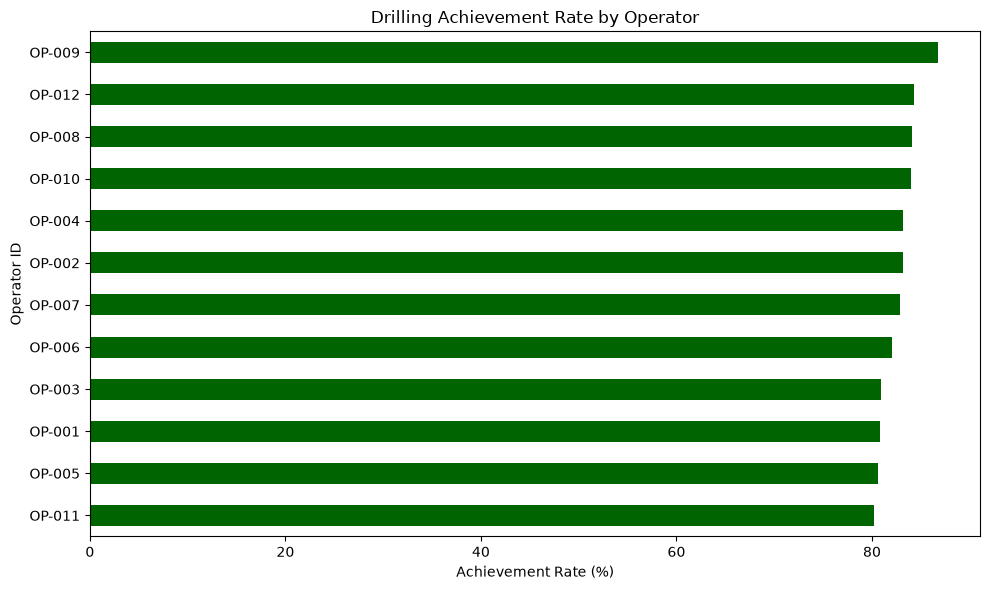

In [8]:
operator_performance["Achievement_Rate"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Drilling Achievement Rate by Operator",
    xlabel="Achievement Rate (%)",
    ylabel="Operator ID",
    color="darkgreen"
)

plt.tight_layout()
plt.show()

In [9]:
sample_performance = df.groupby("Operator_ID").agg(
    Total_Records=("Samples_Collected", "count"),
    Total_Samples=("Samples_Collected", "sum"),
    Avg_Samples=("Samples_Collected", "mean")
)

sample_performance = sample_performance.sort_values(
    by="Total_Samples",
    ascending=False
)

sample_performance.round(2)

,Total_Records,Total_Samples,Avg_Samples
Operator_ID,,,
OP-003,44,328,7.45
OP-002,41,322,7.85
OP-006,35,265,7.57
OP-004,31,262,8.45
OP-007,33,260,7.88
OP-008,28,233,8.32
OP-009,26,227,8.73
OP-005,27,215,7.96
OP-011,27,210,7.78


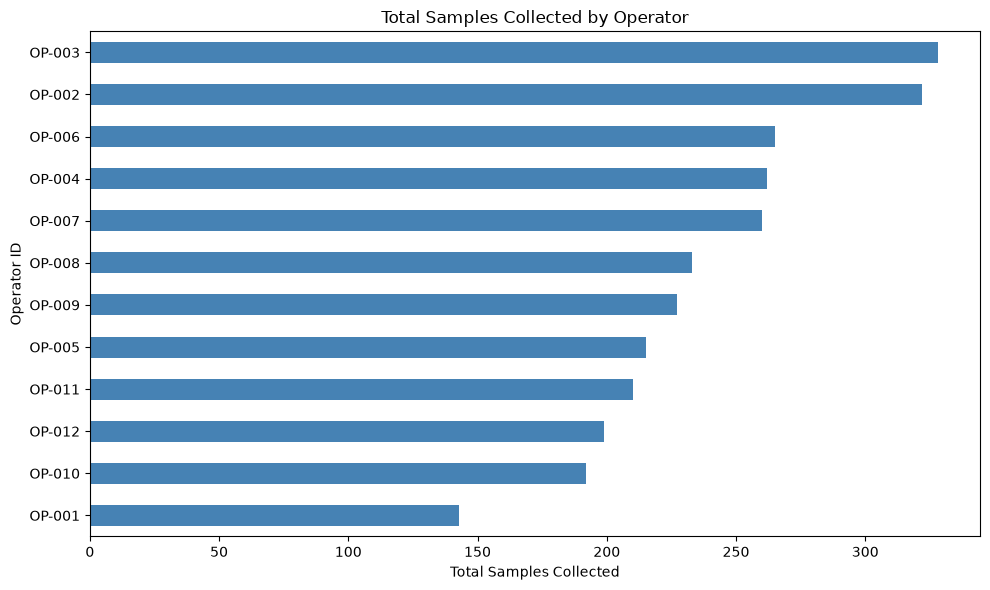

In [10]:
sample_performance["Total_Samples"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Total Samples Collected by Operator",
    xlabel="Total Samples Collected",
    ylabel="Operator ID",
    color="steelblue"
)

plt.tight_layout()
plt.show()

# SQL Analysis

## 1. SQLite Database Setup

In [11]:
import sqlite3

# Create database connection
conn = sqlite3.connect("../data/mining_operations.db")

print("Database connection established successfully!")

Database connection established successfully!


In [12]:
# Export DataFrame to SQLite database
df.to_sql(
    "mining_operations",
    conn,
    if_exists="replace",
    index=False
)

print("Data successfully imported into SQLite!")

Data successfully imported into SQLite!


In [13]:
query = """
SELECT COUNT(*) AS Total_Records
FROM mining_operations;
"""

pd.read_sql_query(query, conn)

,Total_Records
0,360


In [14]:
query = """
SELECT
    SUM(Planned_Meters) AS Total_Planned_Meters,
    SUM(Actual_Meters) AS Total_Actual_Meters,
    ROUND(
        SUM(Actual_Meters) * 100.0 /
        SUM(Planned_Meters), 2
    ) AS Achievement_Rate
FROM mining_operations;
"""

pd.read_sql_query(query, conn)

,Total_Planned_Meters,Total_Actual_Meters,Achievement_Rate
0,35287,29181,82.7


In [15]:
query = """
SELECT
    Rig_ID,
    SUM(Planned_Meters) AS Total_Planned_Meters,
    SUM(Actual_Meters) AS Total_Actual_Meters,
    ROUND(
        SUM(Actual_Meters) * 100.0 /
        SUM(Planned_Meters), 2
    ) AS Achievement_Rate
FROM mining_operations
GROUP BY Rig_ID
ORDER BY Achievement_Rate DESC;
"""

pd.read_sql_query(query, conn)

,Rig_ID,Total_Planned_Meters,Total_Actual_Meters,Achievement_Rate
0,RIG-002,9074,7581,83.55
1,RIG-004,8782,7256,82.62
2,RIG-003,8650,7129,82.42
3,RIG-001,8781,7215,82.17


In [16]:
query = """
SELECT
    Rig_ID,
    ROUND(SUM(Downtime_Hours), 2) AS Total_Downtime_Hours
FROM mining_operations
GROUP BY Rig_ID
ORDER BY Total_Downtime_Hours DESC;
"""

pd.read_sql_query(query, conn)

,Rig_ID,Total_Downtime_Hours
0,RIG-001,189.21
1,RIG-002,186.04
2,RIG-003,171.96
3,RIG-004,166.95


In [17]:
query = """
SELECT
    Rig_ID,
    ROUND(SUM(Fuel_Consumption_L), 2) AS Total_Fuel_Consumption_L
FROM mining_operations
GROUP BY Rig_ID
ORDER BY Total_Fuel_Consumption_L DESC;
"""

pd.read_sql_query(query, conn)

,Rig_ID,Total_Fuel_Consumption_L
0,RIG-002,13205.10
1,RIG-004,12529.12
2,RIG-003,12323.61
3,RIG-001,12276.54


In [18]:
query = """
SELECT
    Rig_ID,
    ROUND(SUM(Fuel_Consumption_L), 2) AS Total_Fuel_L,
    SUM(Actual_Meters) AS Total_Actual_Meters,
    ROUND(
        SUM(Fuel_Consumption_L) * 1.0 /
        SUM(Actual_Meters), 3
    ) AS Fuel_Per_Meter
FROM mining_operations
GROUP BY Rig_ID
ORDER BY Fuel_Per_Meter ASC;
"""

pd.read_sql_query(query, conn)

,Rig_ID,Total_Fuel_L,Total_Actual_Meters,Fuel_Per_Meter
0,RIG-001,12276.54,7215,1.702
1,RIG-004,12529.12,7256,1.727
2,RIG-003,12323.61,7129,1.729
3,RIG-002,13205.10,7581,1.742


In [19]:
query = """
SELECT
    Shift,
    SUM(Planned_Meters) AS Total_Planned_Meters,
    SUM(Actual_Meters) AS Total_Actual_Meters,
    ROUND(SUM(Downtime_Hours), 2) AS Total_Downtime_Hours,
    ROUND(SUM(Fuel_Consumption_L), 2) AS Total_Fuel_L,
    ROUND(
        SUM(Actual_Meters) * 100.0 /
        SUM(Planned_Meters), 2
    ) AS Achievement_Rate
FROM mining_operations
GROUP BY Shift
ORDER BY Achievement_Rate DESC;
"""

pd.read_sql_query(query, conn)

,Shift,Total_Planned_Meters,Total_Actual_Meters,Total_Downtime_Hours,Total_Fuel_L,Achievement_Rate
0,Night,17287,14388,342.03,24766.44,83.23
1,Day,18000,14793,372.13,25567.93,82.18


In [20]:
query = """
SELECT
    Site,
    SUM(Planned_Meters) AS Total_Planned_Meters,
    SUM(Actual_Meters) AS Total_Actual_Meters,
    ROUND(SUM(Downtime_Hours), 2) AS Total_Downtime_Hours,
    ROUND(SUM(Fuel_Consumption_L), 2) AS Total_Fuel_L,
    ROUND(
        SUM(Actual_Meters) * 100.0 /
        SUM(Planned_Meters), 2
    ) AS Achievement_Rate
FROM mining_operations
GROUP BY Site
ORDER BY Achievement_Rate DESC;
"""

pd.read_sql_query(query, conn)

,Site,Total_Planned_Meters,Total_Actual_Meters,Total_Downtime_Hours,Total_Fuel_L,Achievement_Rate
0,North Pit,17855,14796,375.25,25481.64,82.87
1,South Pit,17432,14385,338.91,24852.73,82.52


In [21]:
query = """
SELECT
    Operator_ID,
    COUNT(*) AS Total_Records,
    SUM(Planned_Meters) AS Total_Planned_Meters,
    SUM(Actual_Meters) AS Total_Actual_Meters,
    ROUND(
        SUM(Actual_Meters) * 100.0 /
        SUM(Planned_Meters), 2
    ) AS Achievement_Rate,
    ROUND(
        AVG(Actual_Meters), 2
    ) AS Avg_Actual_Meters
FROM mining_operations
GROUP BY Operator_ID
ORDER BY Achievement_Rate DESC;
"""

pd.read_sql_query(query, conn)

,Operator_ID,Total_Records,Total_Planned_Meters,Total_Actual_Meters,Achievement_Rate,Avg_Actual_Meters
0,OP-009,26,2589,2245,86.71,86.35
1,OP-012,25,2371,1999,84.31,79.96
2,OP-008,28,2771,2331,84.12,83.25
3,OP-010,25,2380,2000,84.03,80.00
4,OP-004,31,3070,2554,83.19,82.39
5,OP-002,41,4045,3363,83.14,82.02
6,OP-007,33,3294,2731,82.91,82.76
7,OP-006,35,3381,2773,82.02,79.23
8,OP-003,44,4194,3394,80.93,77.14
9,OP-001,18,1769,1429,80.78,79.39


In [22]:
query = """
SELECT
    Operator_ID,
    COUNT(*) AS Total_Records,
    SUM(Samples_Collected) AS Total_Samples,
    ROUND(AVG(Samples_Collected), 2) AS Avg_Samples
FROM mining_operations
GROUP BY Operator_ID
ORDER BY Total_Samples DESC;
"""

pd.read_sql_query(query, conn)

,Operator_ID,Total_Records,Total_Samples,Avg_Samples
0,OP-003,44,328,7.45
1,OP-002,41,322,7.85
2,OP-006,35,265,7.57
3,OP-004,31,262,8.45
4,OP-007,33,260,7.88
5,OP-008,28,233,8.32
6,OP-009,26,227,8.73
7,OP-005,27,215,7.96
8,OP-011,27,210,7.78
9,OP-012,25,199,7.96


In [23]:
query = """
SELECT
    Maintenance_Flag,
    COUNT(*) AS Total_Records,
    SUM(Planned_Meters) AS Total_Planned_Meters,
    SUM(Actual_Meters) AS Total_Actual_Meters,
    ROUND(
        SUM(Actual_Meters) * 100.0 /
        SUM(Planned_Meters), 2
    ) AS Achievement_Rate,
    ROUND(AVG(Downtime_Hours), 2) AS Avg_Downtime_Hours,
    ROUND(
        SUM(Fuel_Consumption_L) * 1.0 /
        SUM(Actual_Meters), 3
    ) AS Fuel_Per_Meter
FROM mining_operations
GROUP BY Maintenance_Flag
ORDER BY Maintenance_Flag;
"""

pd.read_sql_query(query, conn)

,Maintenance_Flag,Total_Records,Total_Planned_Meters,Total_Actual_Meters,Achievement_Rate,Avg_Downtime_Hours,Fuel_Per_Meter
0,No,327,32139,26891,83.67,1.74,1.725
1,Yes,33,3148,2290,72.74,4.45,1.722


In [24]:
query = """
SELECT
    Date,
    SUM(Planned_Meters) AS Daily_Planned_Meters,
    SUM(Actual_Meters) AS Daily_Actual_Meters,
    ROUND(
        SUM(Actual_Meters) * 100.0 /
        SUM(Planned_Meters), 2
    ) AS Daily_Achievement_Rate
FROM mining_operations
GROUP BY Date
ORDER BY Date;
"""

daily_sql = pd.read_sql_query(query, conn)

daily_sql.head(10)

,Date,Daily_Planned_Meters,Daily_Actual_Meters,Daily_Achievement_Rate
0,2026-01-01 00:00:00,391,345,88.24
1,2026-01-02 00:00:00,345,287,83.19
2,2026-01-03 00:00:00,334,269,80.54
3,2026-01-04 00:00:00,402,276,68.66
4,2026-01-05 00:00:00,359,326,90.81
5,2026-01-06 00:00:00,420,357,85.00
6,2026-01-07 00:00:00,382,332,86.91
7,2026-01-08 00:00:00,399,266,66.67
8,2026-01-09 00:00:00,402,345,85.82
9,2026-01-10 00:00:00,363,308,84.85


In [25]:
query = """
SELECT
    Date,
    SUM(Actual_Meters) AS Daily_Actual_Meters
FROM mining_operations
GROUP BY Date
ORDER BY Daily_Actual_Meters DESC
LIMIT 1;
"""

pd.read_sql_query(query, conn)

,Date,Daily_Actual_Meters
0,2026-02-05 00:00:00,397


In [26]:
query = """
SELECT
    Date,
    SUM(Actual_Meters) AS Daily_Actual_Meters
FROM mining_operations
GROUP BY Date
ORDER BY Daily_Actual_Meters ASC
LIMIT 1;
"""

pd.read_sql_query(query, conn)

,Date,Daily_Actual_Meters
0,2026-01-25 00:00:00,257


In [28]:
query = """
SELECT
    Date,
    SUM(Actual_Meters) AS Daily_Actual_Meters,
    ROUND(SUM(Downtime_Hours), 2) AS Daily_Downtime_Hours
FROM mining_operations
GROUP BY Date
ORDER BY Daily_Downtime_Hours DESC;
"""

pd.read_sql_query(query, conn).head(10)

,Date,Daily_Actual_Meters,Daily_Downtime_Hours
0,2026-01-08 00:00:00,266,19.29
1,2026-03-15 00:00:00,327,16.21
2,2026-01-04 00:00:00,276,15.58
3,2026-03-27 00:00:00,319,14.77
4,2026-01-12 00:00:00,333,13.56
5,2026-01-30 00:00:00,317,13.16
6,2026-02-13 00:00:00,277,12.66
7,2026-03-13 00:00:00,295,12.18
8,2026-03-11 00:00:00,306,11.97
9,2026-01-18 00:00:00,351,11.85


In [29]:
correlation = daily_sql.merge(
    pd.read_sql_query(
        """
        SELECT
            Date,
            SUM(Downtime_Hours) AS Daily_Downtime_Hours
        FROM mining_operations
        GROUP BY Date
        ORDER BY Date;
        """,
        conn
    ),
    on="Date"
)

correlation[
    ["Daily_Actual_Meters", "Daily_Downtime_Hours"]
].corr()

,Daily_Actual_Meters,Daily_Downtime_Hours
Daily_Actual_Meters,1.000000,-0.385797
Daily_Downtime_Hours,-0.385797,1.000000


In [30]:
# Read the SQL analysis file
with open("../sql/mining_operations_analysis.sql", "r", encoding="utf-8") as file:
    sql_script = file.read()

# Split the script into individual SQL statements
statements = [
    statement.strip()
    for statement in sql_script.split(";")
    if statement.strip()
]

# Execute and validate each SQL query
for i, statement in enumerate(statements, start=1):
    cursor = conn.execute(statement)

    if cursor.description:
        results = cursor.fetchall()
        print(f"Query {i}: SUCCESS - {len(results)} rows returned")
    else:
        print(f"Query {i}: SUCCESS")

Query 1: SUCCESS - 1 rows returned
Query 2: SUCCESS - 4 rows returned
Query 3: SUCCESS - 4 rows returned
Query 4: SUCCESS - 4 rows returned


In [31]:
# Read the SQL analysis file
with open("../sql/mining_operations_analysis.sql", "r", encoding="utf-8") as file:
    sql_script = file.read()

# Split the script into individual SQL statements
statements = [
    statement.strip()
    for statement in sql_script.split(";")
    if statement.strip()
]

# Execute and validate each SQL query
for i, statement in enumerate(statements, start=1):
    cursor = conn.execute(statement)

    if cursor.description:
        results = cursor.fetchall()
        print(f"Query {i}: SUCCESS - {len(results)} rows returned")
    else:
        print(f"Query {i}: SUCCESS")

Query 1: SUCCESS - 1 rows returned
Query 2: SUCCESS - 4 rows returned
Query 3: SUCCESS - 4 rows returned
Query 4: SUCCESS - 4 rows returned
Query 5: SUCCESS - 4 rows returned
Query 6: SUCCESS - 2 rows returned
Query 7: SUCCESS - 2 rows returned
Query 8: SUCCESS - 12 rows returned
Query 9: SUCCESS - 12 rows returned
Query 10: SUCCESS - 2 rows returned
Query 11: SUCCESS - 90 rows returned
